# 07 · Neural Networks — From One Neuron to Deep Learning

Neural networks power image recognition, speech, translation and LLMs. Underneath, they're built from pieces you already know: **linear models**, **non-linear squashing functions**, and **gradient descent**.

**What you'll learn**
1. A neuron = logistic regression. Why one neuron can't solve XOR, and why stacking layers + non-linearity can
2. The **forward pass** (computing predictions) and **backpropagation** (computing gradients with the chain rule)
3. 🐍 A tiny **autograd engine** in pure Python that does backprop automatically, used to train a network
4. 🔢 A fully-vectorised NumPy MLP with hand-written backprop, plus **gradient checking**
5. Practical training: activations, initialisation, optimisers (SGD, momentum, Adam), overfitting & dropout
6. 📦 The same network in **PyTorch**, as used in industry

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, random
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0)

def plot_boundary(predict, X, y, ax=None, title="", h=200):
    ax = ax or plt.gca()
    x0, x1 = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, h),
                         np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, h))
    Z = np.asarray(predict(np.c_[x0.ravel(), x1.ravel()])).reshape(x0.shape)
    ax.contourf(x0, x1, Z, alpha=0.35, cmap="coolwarm", levels=20)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=18); ax.set_title(title)

## 1. A single neuron

A neuron takes inputs, computes a weighted sum plus a bias, and passes it through an **activation function**:
$$ a = f(w_1x_1 + w_2x_2 + \dots + b) = f(\mathbf{w}\cdot\mathbf{x} + b) $$
With $f$ = sigmoid, this is **exactly logistic regression** (notebook 02). So one neuron draws one straight line.

### The XOR problem
XOR outputs 1 when exactly one input is 1. No single straight line separates the 1s from the 0s — this famously stalled neural-network research in 1969.

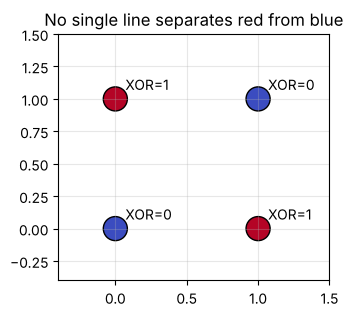

In [2]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
y_xor = np.array([0, 1, 1, 0])
plt.figure(figsize=(3.5, 3.2))
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=300, edgecolor="k")
for (a, b), t in zip(X_xor, y_xor): plt.text(a + 0.07, b + 0.07, f"XOR={t}")
plt.xlim(-.4, 1.5); plt.ylim(-.4, 1.5); plt.title("No single line separates red from blue"); plt.show()

## 2. The fix: hidden layers + non-linearity

A **multi-layer perceptron (MLP)** stacks layers of neurons:
```
input x ──► hidden layer (many neurons, each with an activation) ──► output layer ──► prediction
```
In matrix form, for one hidden layer:
$$ \mathbf{h} = f(W_1\mathbf{x} + \mathbf{b}_1), \qquad \hat{y} = g(W_2\mathbf{h} + \mathbf{b}_2) $$

The hidden layer **creates new features** (each hidden neuron draws its own line), and the output layer combines them. For XOR: one hidden neuron learns "OR", another learns "AND", and the output computes "OR and not AND".

**Why the activation $f$ must be non-linear:** without it, $W_2(W_1\mathbf{x}) = (W_2W_1)\mathbf{x}$ — a stack of linear layers collapses into one linear layer, no matter how deep. Non-linearity is what gives depth its power. (With enough hidden neurons, an MLP can approximate *any* continuous function — the **universal approximation theorem**.)

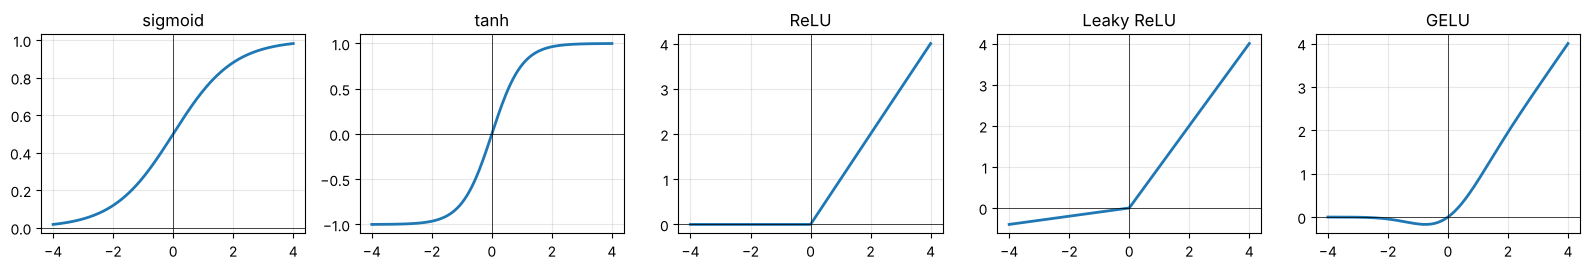

In [3]:
z = np.linspace(-4, 4, 200)
acts = {"sigmoid": 1 / (1 + np.exp(-z)), "tanh": np.tanh(z), "ReLU": np.maximum(0, z),
        "Leaky ReLU": np.where(z > 0, z, 0.1 * z), "GELU": 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z ** 3)))}
fig, axes = plt.subplots(1, 5, figsize=(16, 2.8))
for ax, (name, a) in zip(axes, acts.items()):
    ax.plot(z, a, lw=2); ax.set_title(name); ax.axhline(0, c="k", lw=0.5); ax.axvline(0, c="k", lw=0.5)
plt.tight_layout(); plt.show()

| Activation | Notes |
|---|---|
| **sigmoid** | output (0,1); used at the output for binary probabilities; in hidden layers its gradients **vanish** for large \|z\| |
| **tanh** | output (−1,1), zero-centred; still saturates |
| **ReLU** max(0,z) | default for hidden layers: cheap, doesn't saturate for z>0. Can "die" (stuck at 0) |
| **Leaky ReLU / GELU** | fix dead ReLUs; GELU is used in transformers |
| **softmax** | output layer for multi-class probabilities |

## 3. Backpropagation — how the network learns

Training is still gradient descent: compute the loss, get the gradient of the loss with respect to **every** weight, step downhill. **Backpropagation** is just an efficient way to get all those gradients using the **chain rule**.

### The chain rule on a tiny example
Say $L = (wx + b - y)^2$. Break it into steps (a **computational graph**):
```
z = w·x        s = z + b        e = s − y        L = e²
```
Going **forward** computes values. Going **backward**, each step multiplies the gradient flowing in by its own *local* derivative:
$$ \frac{\partial L}{\partial e} = 2e,\quad \frac{\partial L}{\partial s} = \frac{\partial L}{\partial e}\cdot 1,\quad \frac{\partial L}{\partial b} = \frac{\partial L}{\partial s}\cdot 1,\quad \frac{\partial L}{\partial w} = \frac{\partial L}{\partial s}\cdot x $$

That's all backprop is: **forward pass to compute values, backward pass multiplying local derivatives, from the loss back to each weight.** One backward pass gives *every* gradient for roughly the cost of one forward pass — which is why we can train networks with billions of weights.

## 4. 🐍 Pure Python: a tiny autograd engine

Instead of deriving gradients by hand for every network, we build a `Value` class that **records the computational graph** as you do maths, then walks it backwards. This is exactly how PyTorch works, in ~50 lines (inspired by Andrej Karpathy's *micrograd*).

In [4]:
class Value:
    """A number that remembers how it was computed, so it can backpropagate gradients."""
    def __init__(self, data, children=(), op=""):
        self.data, self.grad = data, 0.0
        self._backward = lambda: None          # how to push my gradient to my children
        self._prev, self._op = set(children), op

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():                       # d(a+b)/da = 1, d(a+b)/db = 1
            self.grad += out.grad; other.grad += out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():                       # d(a·b)/da = b, d(a·b)/db = a
            self.grad += other.data * out.grad; other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, k):
        out = Value(self.data ** k, (self,), f"**{k}")
        def _backward():
            self.grad += k * self.data ** (k - 1) * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), "tanh")
        def _backward():                       # d tanh(x)/dx = 1 − tanh²(x)
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward
        return out

    def backward(self):
        # visit nodes in reverse topological order (each node after everything that depends on it)
        order, seen = [], set()
        def build(v):
            if v not in seen:
                seen.add(v)
                for c in v._prev: build(c)
                order.append(v)
        build(self)
        self.grad = 1.0                        # dL/dL = 1
        for v in reversed(order):
            v._backward()

    # conveniences so we can write natural maths
    __radd__ = __add__; __rmul__ = __mul__
    def __neg__(self): return self * -1
    def __sub__(self, other): return self + (-other)
    def __repr__(self): return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

# The tiny example from Section 3: L = (w·x + b − y)²
w, x, b, y = Value(2.0), Value(3.0), Value(1.0), Value(5.0)
L = (w * x + b - y) ** 2
L.backward()
print("L =", L.data, "| dL/dw =", w.grad, "(by hand: 2·(wx+b−y)·x = 2·2·3 = 12) | dL/db =", b.grad, "(by hand: 4)")

L = 4.0 | dL/dw = 12.0 (by hand: 2·(wx+b−y)·x = 2·2·3 = 12) | dL/db = 4.0 (by hand: 4)


In [5]:
# 🐍 A neural network built from Values
class Neuron:
    def __init__(self, n_in, act=True):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(n_in)]
        self.b = Value(0.0); self.act = act
    def __call__(self, x):
        z = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        return z.tanh() if self.act else z
    def params(self): return self.w + [self.b]

class Layer:
    def __init__(self, n_in, n_out, act=True): self.neurons = [Neuron(n_in, act) for _ in range(n_out)]
    def __call__(self, x): return [n(x) for n in self.neurons]
    def params(self): return [p for n in self.neurons for p in n.params()]

class MLP:
    def __init__(self, sizes):               # e.g. [2, 4, 1]: 2 inputs, 4 hidden, 1 output
        self.layers = [Layer(a, b, act=(i < len(sizes) - 2)) for i, (a, b) in enumerate(zip(sizes, sizes[1:]))]
    def __call__(self, x):
        for layer in self.layers: x = layer(x)
        return x[0] if len(x) == 1 else x
    def params(self): return [p for l in self.layers for p in l.params()]

random.seed(1)
net = MLP([2, 4, 1])
targets = [-1.0, 1.0, 1.0, -1.0]             # XOR with ±1 targets (matches tanh's range)
for step in range(200):
    preds = [net(xi) for xi in X_xor.tolist()]
    loss = sum(((p - t) ** 2 for p, t in zip(preds, targets)), Value(0.0))   # squared error
    for p in net.params(): p.grad = 0.0      # reset gradients (they accumulate!)
    loss.backward()                          # backprop through the whole network
    for p in net.params(): p.data -= 0.05 * p.grad     # gradient descent step
    if step % 50 == 0 or step == 199:
        print(f"step {step:3d}  loss {loss.data:.4f}  predictions {[round(p.data, 2) for p in preds]}")
print(f"XOR solved ✔  ({len(net.params())} parameters)")

step   0  loss 4.1054  predictions [0.0, -0.2, 0.0, -0.17]
step  50  loss 0.0249  predictions [-0.96, 0.91, 0.92, -0.9]
step 100  loss 0.0000  predictions [-1.0, 1.0, 1.0, -1.0]
step 150  loss 0.0000  predictions [-1.0, 1.0, 1.0, -1.0]
step 199  loss 0.0000  predictions [-1.0, 1.0, 1.0, -1.0]
XOR solved ✔  (17 parameters)


That's a complete deep-learning framework in miniature: build a graph during the forward pass, call `.backward()`, update weights. It works on single numbers, so it's slow — real frameworks do the same thing on whole **tensors** (arrays) at once. Let's do that next.

## 5. 🔢 NumPy MLP with hand-written backprop

We now process a whole **batch** of samples as a matrix. For a network `input → Linear → ReLU → Linear → softmax`, with $X$ of shape (n, d):

**Forward**
$$ Z_1 = XW_1 + b_1,\quad H = \text{ReLU}(Z_1),\quad Z_2 = HW_2 + b_2,\quad P = \text{softmax}(Z_2),\quad L = -\tfrac{1}{n}\textstyle\sum \log P_{\text{true}} $$

**Backward** (each line is one chain-rule step; shapes in brackets)
$$ dZ_2 = (P - Y)/n \;[n{\times}K] \qquad \text{(softmax + cross-entropy simplify beautifully, as in notebook 02)} $$
$$ dW_2 = H^\top dZ_2,\quad db_2 = \textstyle\sum_{\text{rows}} dZ_2,\quad dH = dZ_2 W_2^\top $$
$$ dZ_1 = dH \odot [Z_1 > 0] \qquad \text{(ReLU passes gradient only where it was active)} $$
$$ dW_1 = X^\top dZ_1,\quad db_1 = \textstyle\sum_{\text{rows}} dZ_1 $$

**Shape rule of thumb:** a gradient always has the same shape as the thing it's the gradient of. If your shapes don't match, your maths is wrong.

In [6]:
def softmax(Z):
    Z = Z - Z.max(1, keepdims=True); E = np.exp(Z); return E / E.sum(1, keepdims=True)

class MLPNP:
    """Fully-connected network with ReLU hidden layers and a softmax output. Any number of layers."""
    def __init__(self, sizes, seed=0):
        r = np.random.default_rng(seed)
        # He initialisation: variance 2/fan_in keeps activations from shrinking/exploding through ReLU layers
        self.W = [r.normal(0, np.sqrt(2 / a), (a, b)) for a, b in zip(sizes, sizes[1:])]
        self.b = [np.zeros(b) for b in sizes[1:]]

    def forward(self, X):
        self.cache = [X]                                   # remember inputs of each layer for backprop
        A = X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            Z = A @ W + b
            A = softmax(Z) if i == len(self.W) - 1 else np.maximum(0, Z)
            self.cache.append(A)
        return A

    def loss(self, P, y):
        return -np.mean(np.log(P[np.arange(len(y)), y] + 1e-12))

    def backward(self, y):
        n = len(y); P = self.cache[-1]
        dZ = P.copy(); dZ[np.arange(n), y] -= 1; dZ /= n      # (P − Y)/n
        self.dW, self.db = [None] * len(self.W), [None] * len(self.W)
        for i in reversed(range(len(self.W))):
            A_prev = self.cache[i]
            self.dW[i] = A_prev.T @ dZ
            self.db[i] = dZ.sum(0)
            if i > 0:
                dZ = (dZ @ self.W[i].T) * (A_prev > 0)        # back through ReLU of previous layer

    def predict(self, X):
        return self.forward(X).argmax(1)

    def params_and_grads(self):
        return list(zip(self.W + self.b, self.dW + self.db))

### Gradient checking — trust, but verify

Hand-written backprop is easy to get subtly wrong. Compare against the definition of a derivative, using a tiny nudge ε:
$$ \frac{\partial L}{\partial w} \approx \frac{L(w + \varepsilon) - L(w - \varepsilon)}{2\varepsilon} $$
This is far too slow for training (two forward passes *per weight*), but perfect for testing.

In [7]:
from sklearn.datasets import make_moons
Xm, ym = make_moons(200, noise=0.2, random_state=0)
net = MLPNP([2, 8, 8, 2], seed=1)
net.forward(Xm); net.backward(ym)

eps, worst = 1e-5, 0.0
for W, dW in zip(net.W, net.dW):
    for idx in [tuple(rng.integers(0, s) for s in W.shape) for _ in range(5)]:
        old = W[idx]
        W[idx] = old + eps; lp = net.loss(net.forward(Xm), ym)
        W[idx] = old - eps; lm = net.loss(net.forward(Xm), ym)
        W[idx] = old
        numeric = (lp - lm) / (2 * eps)
        rel = abs(numeric - dW[idx]) / max(1e-8, abs(numeric) + abs(dW[idx]))
        worst = max(worst, rel)
print(f"worst relative error between backprop and numerical gradient: {worst:.2e}  ({'✔ correct' if worst < 1e-5 else '✘ bug!'})")

worst relative error between backprop and numerical gradient: 4.86e-08  (✔ correct)


### Training with mini-batches and different optimisers

- **SGD:** $w \leftarrow w - \eta\, g$
- **Momentum:** keep a running "velocity" $v \leftarrow \beta v + g$, step $w \leftarrow w - \eta v$. Like a ball rolling downhill — it speeds through flat regions and smooths out zig-zags.
- **Adam:** momentum **plus** a per-weight step size scaled by the running average of squared gradients — weights with consistently large gradients take smaller steps. The most common default.

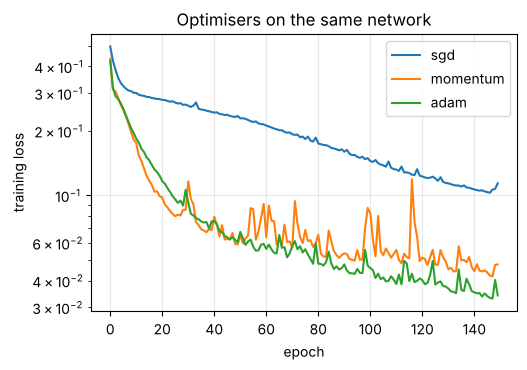

In [8]:
class Optimizer:
    def __init__(self, kind="sgd", lr=0.1, beta1=0.9, beta2=0.999):
        self.kind, self.lr, self.b1, self.b2, self.t, self.state = kind, lr, beta1, beta2, 0, {}
    def step(self, pairs):
        self.t += 1
        for i, (p, g) in enumerate(pairs):
            if self.kind == "sgd":
                p -= self.lr * g
            elif self.kind == "momentum":
                v = self.state.setdefault(i, np.zeros_like(p)); v *= self.b1; v += g
                p -= self.lr * v
            elif self.kind == "adam":
                m, v = self.state.setdefault(i, (np.zeros_like(p), np.zeros_like(p)))
                m *= self.b1; m += (1 - self.b1) * g                 # running mean of gradients
                v *= self.b2; v += (1 - self.b2) * g * g             # running mean of squared gradients
                m_hat, v_hat = m / (1 - self.b1 ** self.t), v / (1 - self.b2 ** self.t)   # bias correction
                p -= self.lr * m_hat / (np.sqrt(v_hat) + 1e-8)

def train(net, X, y, opt, epochs=200, batch=32, seed=0, X_val=None, y_val=None):
    r = np.random.default_rng(seed); hist = {"loss": [], "val_acc": []}
    for _ in range(epochs):
        idx = r.permutation(len(y))
        for s in range(0, len(y), batch):
            bi = idx[s:s + batch]
            net.forward(X[bi]); net.backward(y[bi]); opt.step(net.params_and_grads())
        hist["loss"].append(net.loss(net.forward(X), y))
        if X_val is not None: hist["val_acc"].append(np.mean(net.predict(X_val) == y_val))
    return hist

curves = {}
for kind, lr in [("sgd", 0.05), ("momentum", 0.05), ("adam", 0.01)]:
    curves[kind] = train(MLPNP([2, 16, 16, 2], seed=0), Xm, ym, Optimizer(kind, lr), epochs=150)["loss"]
for k, c in curves.items(): plt.plot(c, label=k)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("training loss"); plt.legend(); plt.title("Optimisers on the same network"); plt.show()

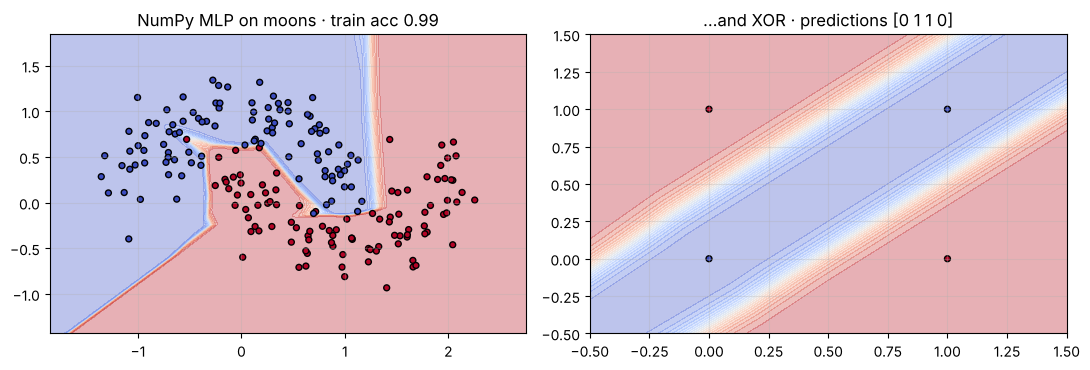

In [9]:
net = MLPNP([2, 16, 16, 2], seed=0); train(net, Xm, ym, Optimizer("adam", 0.01), epochs=300)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
plot_boundary(lambda G: net.forward(G)[:, 1], Xm, ym, ax[0], f"NumPy MLP on moons · train acc {np.mean(net.predict(Xm) == ym):.2f}")
xnet = MLPNP([2, 8, 2], seed=3); train(xnet, X_xor, y_xor, Optimizer("adam", 0.05), epochs=500, batch=4)
plot_boundary(lambda G: xnet.forward(G)[:, 1], X_xor, y_xor, ax[1], f"…and XOR · predictions {xnet.predict(X_xor)}")
plt.tight_layout(); plt.show()

## 6. A real task: handwritten digits

8×8 images → 64 inputs → hidden layers → 10 outputs (one per digit). Note we **standardise** inputs and watch a **validation** set during training.

our NumPy network — test accuracy: 0.9756


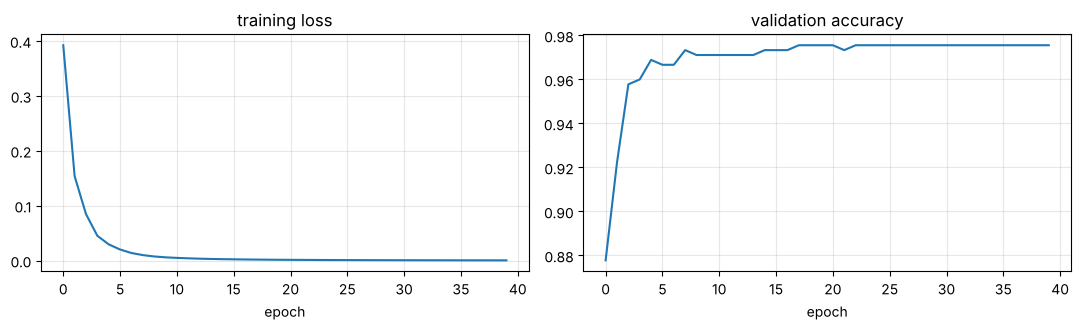

In [10]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
Xd, yd = load_digits(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.25, random_state=0, stratify=yd)
sc = StandardScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)

digit_net = MLPNP([64, 64, 32, 10], seed=0)
h = train(digit_net, Xtr_s, ytr, Optimizer("adam", 0.003), epochs=40, X_val=Xte_s, y_val=yte)
print(f"our NumPy network — test accuracy: {np.mean(digit_net.predict(Xte_s) == yte):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(h["loss"]); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h["val_acc"]); ax[1].set_title("validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

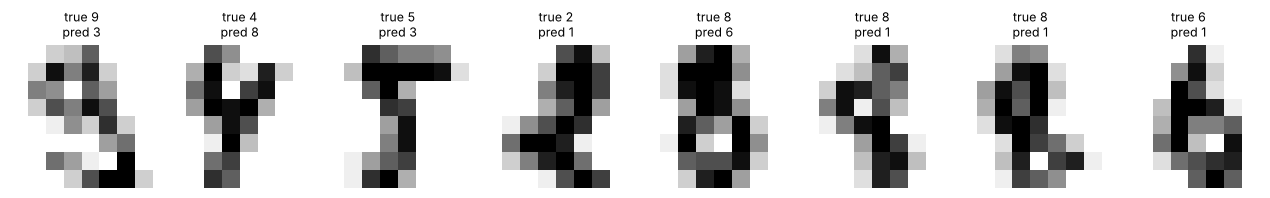

In [11]:
# Where does it go wrong?
pred = digit_net.predict(Xte_s); wrong = np.where(pred != yte)[0][:8]
fig, axes = plt.subplots(1, len(wrong), figsize=(1.6 * len(wrong), 2))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(Xte[i].reshape(8, 8), cmap="gray_r"); ax.set_title(f"true {yte[i]}\npred {pred[i]}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Training pitfalls and remedies

| Symptom | Likely cause | Fix |
|---|---|---|
| Loss is NaN / explodes | learning rate too high, bad init | lower lr, gradient clipping, check data for NaN |
| Loss barely moves | lr too low, dead ReLUs, vanishing gradients (sigmoid/tanh in deep nets) | raise lr, ReLU/GELU, He init, normalisation layers |
| Train ≫ validation accuracy | **overfitting** | more data, data augmentation, **dropout**, weight decay (L2), early stopping, smaller net |
| Both low | underfitting | bigger network, train longer, better features |

**Dropout:** during training, randomly zero each hidden activation with probability p (and scale survivors by 1/(1−p)). The network can't rely on any single neuron, which acts like training an ensemble of thinned networks. Turned **off** at test time.

**Batch / Layer normalisation:** re-centre and re-scale activations inside the network so each layer sees well-behaved inputs; makes deep networks much easier to train.

**Initialisation:** weights that are too small make signals shrink to 0 layer by layer; too big and they explode. Xavier/Glorot (tanh) and **He** (ReLU) init pick the variance to keep the signal steady:

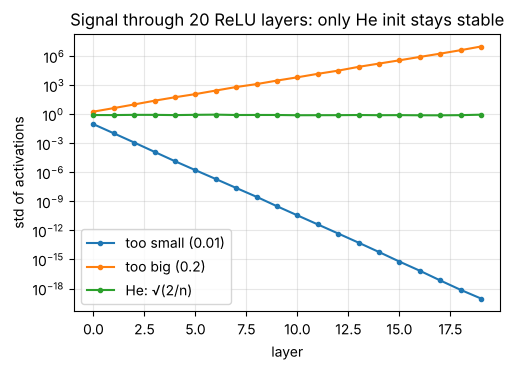

In [12]:
def activation_stds(init_std_fn, depth=20, width=256):
    a = rng.normal(size=(500, width)); stds = []
    for _ in range(depth):
        a = np.maximum(0, a @ rng.normal(0, init_std_fn(width), (width, width))); stds.append(a.std())
    return stds
for name, f in [("too small (0.01)", lambda n: 0.01), ("too big (0.2)", lambda n: 0.2), ("He: √(2/n)", lambda n: np.sqrt(2 / n))]:
    plt.plot(activation_stds(f), "o-", ms=3, label=name)
plt.yscale("log"); plt.xlabel("layer"); plt.ylabel("std of activations"); plt.legend()
plt.title("Signal through 20 ReLU layers: only He init stays stable"); plt.show()

## 8. 📦 PyTorch — the same network, the industry way

PyTorch gives you tensors (like NumPy arrays, but can run on GPU) plus **autograd** — the same idea as our `Value` class, so you never write backward passes by hand. The training loop has five lines you'll write thousands of times:
```python
pred = model(xb)              # 1. forward
loss = loss_fn(pred, yb)      # 2. loss
optimizer.zero_grad()         # 3. reset gradients (they accumulate — like our p.grad = 0)
loss.backward()               # 4. backprop
optimizer.step()              # 5. update weights
```

In [13]:
import torch
from torch import nn
torch.manual_seed(0)

Xtr_t, ytr_t = torch.tensor(Xtr_s, dtype=torch.float32), torch.tensor(ytr)
Xte_t, yte_t = torch.tensor(Xte_s, dtype=torch.float32), torch.tensor(yte)

model = nn.Sequential(
    nn.Linear(64, 64), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 10),              # raw scores ("logits"); CrossEntropyLoss applies softmax internally
)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.003, weight_decay=1e-4)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xtr_t, ytr_t), batch_size=32, shuffle=True)

for epoch in range(40):
    model.train()                                  # dropout ON
    total = 0.0
    for xb, yb in loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        total += loss.item() * len(xb)
    if epoch % 10 == 9:
        model.eval()                               # dropout OFF
        with torch.no_grad():                      # no graph needed for evaluation
            acc = (model(Xte_t).argmax(1) == yte_t).float().mean().item()
        print(f"epoch {epoch + 1:2d}  mean train loss {total / len(ytr_t):.4f}  test acc {acc:.4f}")
print("parameters:", sum(p.numel() for p in model.parameters()))

epoch 10  mean train loss 0.0412  test acc 0.9711


epoch 20  mean train loss 0.0160  test acc 0.9711


epoch 30  mean train loss 0.0110  test acc 0.9622


epoch 40  mean train loss 0.0138  test acc 0.9644
parameters: 6570


In [14]:
# PyTorch's autograd agrees with our tiny engine on the Section-3 example
w, x, b, y = (torch.tensor(v, requires_grad=True) for v in (2.0, 3.0, 1.0, 5.0))
L = (w * x + b - y) ** 2; L.backward()
print("PyTorch: dL/dw =", w.grad.item(), " dL/db =", b.grad.item(), " (our Value class: 12.0 and 4.0)")

PyTorch: dL/dw = 12.0  dL/db = 4.0  (our Value class: 12.0 and 4.0)


## 9. Where to go from here
This MLP is the foundation of all deep learning. The famous architectures change *how layers are connected*, not the training recipe:
- **CNNs** (images): share small filters across the image — translation-equivariant, far fewer weights.
- **RNNs / LSTMs** (sequences): reuse the same weights at each time step, carrying a hidden state.
- **Transformers** (text, now everything): **attention** lets every position look at every other position.

All are trained with exactly what you built here: forward pass → loss → backprop → optimiser step.

## Key takeaways
- A neuron = linear model + activation; layers of neurons + **non-linearity** can learn any function.
- **Backpropagation** = the chain rule applied backwards through the computational graph; one backward pass gives every gradient.
- **Gradient-check** hand-written gradients. Initialise carefully (He for ReLU). Adam is a strong default optimiser.
- Fight overfitting with validation monitoring, dropout, weight decay, early stopping and more data.

## Exercises
1. Add `relu()` and `exp()` methods to `Value`, then build a ReLU network with it.
2. Add **dropout** to `MLPNP.forward` (training mode only) and check it narrows the train/validation gap on the digits.
3. Change `MLPNP` to sigmoid hidden activations and a 6-layer network. What happens to training speed, and why? (Hint: vanishing gradients.)
4. In PyTorch, add `nn.BatchNorm1d` after each hidden `nn.Linear`. Does it train faster?

In [15]:
# Exercise 1 — solution
def relu(self):
    out = Value(max(0.0, self.data), (self,), "relu")
    def _backward(): self.grad += (out.data > 0) * out.grad
    out._backward = _backward
    return out
def exp(self):
    e = math.exp(self.data); out = Value(e, (self,), "exp")
    def _backward(): self.grad += e * out.grad            # d eˣ/dx = eˣ
    out._backward = _backward
    return out
Value.relu, Value.exp = relu, exp

a = Value(1.5); out = (a * 2).relu() + a.exp(); out.backward()
print("d/da [relu(2a) + e^a] at a=1.5 =", round(a.grad, 4), " (expected 2 + e^1.5 =", round(2 + math.exp(1.5), 4), ")")

d/da [relu(2a) + e^a] at a=1.5 = 6.4817  (expected 2 + e^1.5 = 6.4817 )


**🎉 You've finished the core series.** Recap of the path: Python & NumPy → linear models & gradient descent → logistic regression → honest evaluation → KNN/NB/SVM → trees & ensembles → unsupervised learning → neural networks.

**Next:** [08 · Data Preparation & EDA](08_data_preparation_and_eda.ipynb) — the practical track: working with a real, messy dataset from raw CSV to a shipped, explained model.

*Going deeper / interview prep:* `DL_Interview_Notes.md` Parts 1–4 (backprop, init, normalisation, optimisers, regularisation) and Parts 5–7 (CNNs, RNNs, transformers) · `Calculus_Notes.md` Part 3 (chain rule & autodiff, forward vs reverse mode) · code: `dl_from_scratch.py` (CNN, LSTM, attention, transformer from scratch) · `ml_from_scratch.py` → `MLP`.